# Lesson 2 — One Gaussian on a Line: Taking Apart the Bell Curve

[Course outline and setup](../../README.md) · [Previous lesson](lesson-01.ipynb) · [Русская версия](../ru/lesson-02.ipynb) · [Next: a Gaussian on a plane](lesson-03.ipynb)

Let's take one bell curve and see how it works. First, we'll move it around and change its width. Then we'll pick a point and work out, by hand, why it sits at that particular height. Along the way, we'll unpack every operation in the formula.

Ordinary arithmetic and the ability to run a Python cell are enough to get started. Derivatives, matrices, and probability theory can wait. For now, we're working with a **one-dimensional** Gaussian: give it one coordinate and get one number back.

In lesson 1, we built an image from soft spots. Now we'll draw a line through one spot and see how its influence changes along that line: stronger in the middle, weaker farther away. We'll describe that influence with a number called a weight. Pixel colors and overlapping spots will come in later lessons.

## 1. Look at It and Try It First

Run the cells from top to bottom. The first finds the course folder and loads the code that draws the plots and sliders. You can simply run it for now. Below, we'll calculate the Gaussian itself step by step, using ordinary arithmetic.

The second cell brings up the plot and sliders. On GitHub, you'll see a saved image. To move the sliders, open the notebook in Jupyter; the README explains how.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

LANG = "en"

course_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "course_demos.py").is_file()),
    None,
)
if course_root is None:
    raise FileNotFoundError("Open this notebook from the course repository.")
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from IPython.display import display
from course_demos import (
    gaussian_lab,
    gaussian_figure,
    construction_figure,
    width_figure,
)

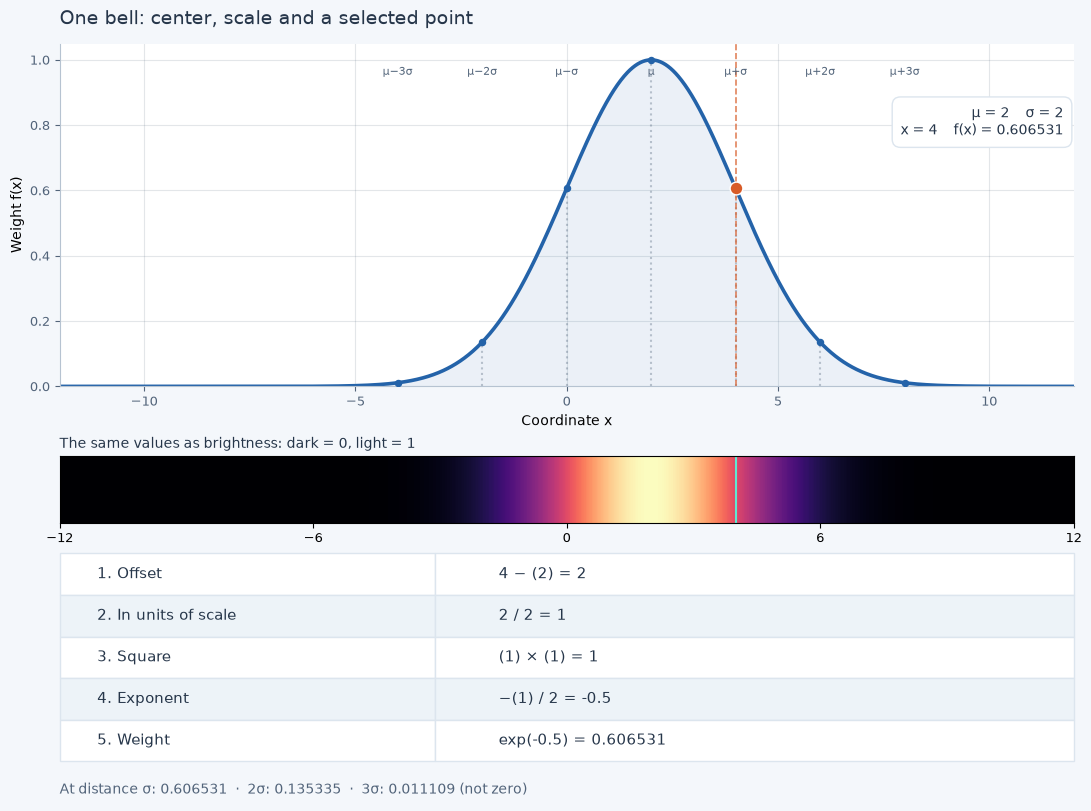

In [2]:
display(gaussian_figure(mu=2, sigma=2, x=4, language=LANG))
display(gaussian_lab(language=LANG))

Leave the formula for a moment. Let's try three things first:

1. Move the center from 2 to −2. The bell moves, but its shape and peak height stay the same.
2. Return the center to 2 and reduce the width from 2 to 1. The bell becomes narrower, while its peak remains at 1.
3. Return the width to 2 and move the point along the graph. We're checking the weight at a different place each time; the bell itself stays the same.

The horizontal axis gives the coordinate along the line. The vertical axis gives the **weight**: how strongly the Gaussian contributes there. We're not measuring the height of a physical object. The strip below the graph shows the same weight through brightness: greater weight → brighter.

The axes stay fixed, so you can see the bell move when you move its center. For the calculations below, return to **center 2 and width 2**. We'll start at point **4**.

## 2. How to Read One Point on the Graph

Imagine a ruler. We selected the mark at 4 and want to know the weight there.

| Notation | Read it as | What it means here |
|---|---|---|
| $x$ | “x” | The coordinate we inspect: 4 |
| $\mu$ | “mu” | The center of the bell: 2 |
| $\sigma$ | “sigma” | The width scale: 2; it must be greater than zero |
| $f(x)$ | “f of x” | The weight we'll get at point $x$ |

The parentheses in $f(x)$ identify the function's input. This is **not** multiplication of a letter $f$ by a number $x$. Here, “function” simply means a rule: receive a coordinate, perform some operations, return a number.

For our bell, $f(2)=1$: the center has the maximum weight. Writing $f(4)$ means “calculate the weight at 4.” We will obtain approximately 0.606531.

Changing $\mu$ or $\sigma$ changes the bell itself. Changing $x$ just picks where on that bell we check the weight.

## 3. First Step: Measure from the Center

A coordinate alone does not tell us whether we are far from the bell. The point 100 can be exactly at its center if the center is also 100.

We therefore subtract the center first:

$$
d=x-\mu.
$$

Let's call this **displacement from the center** $d$, so we don't have to write out the subtraction every time. With $x=4$ and $\mu=2$:

$$
d=4-2=2.
$$

We are two units to the right of the center. Now take $x=0$:

$$
d=0-2=-2.
$$

We are two units to the left. The sign records the side, while the magnitude 2 records how far away we are. At the center itself, $d=2-2=0$.

We want points equally far to the left and right to have the same weight. So far, we've got different numbers: $2$ and $-2$. In two steps, squaring will make them match.

## 4. Second Step: Measure Displacement in Units of Width

We're two units from the center. That could be far away for a narrow spot or quite close for a wide one. Distance alone isn't enough: we also need to compare it with the spot's width.

$$
u=\frac{d}{\sigma}.
$$

The fraction bar means division. We'll call the result $u$: we're now measuring **displacement in units of width**. Put in our numbers:

$$
u=\frac{2}{2}=1.
$$

The point is one width to the right of the center. On the left, we obtain $(-2)/2=-1$.

If the point and center stay fixed but we set $\sigma=1$, then $u=2/1=2$: the same point is now two widths from the center. If we set $\sigma=4$, then $u=2/4=0.5$: only half a width away.

Use the same units for $x,\mu,\sigma$. If the coordinates are in centimeters, the width must be in centimeters too. In “2 cm / 2 cm,” the centimeters cancel, leaving just 1. We call this number **dimensionless**. We've found how many widths separate the point from the center; choosing centimeters or meters doesn't change that answer.

$\sigma$ sets the width scale. It doesn't measure the spot's full width or mark a boundary: our bell has no sharp edge at all.

## 5. Third Step: Make the Left and Right Sides Match

Square the relative displacement:

$$
q=u^2=u\cdot u.
$$

The small raised 2 means “multiply the number by itself.” The centered dot means multiplication.

To the right of the center:

$$
q=1^2=1\cdot1=1.
$$

To the left:

$$
q=(-1)^2=(-1)\cdot(-1)=1.
$$

The product of two negative numbers is positive, so both sides produce the same result. At the center, $q=0^2=0$. Two widths away, $q=2^2=4$; three widths away, $q=3^2=9$.

After squaring, the left and right sides match, and the numbers grow faster as we move away from the center. So far, though, we've got the opposite of what we need: zero at the center, more farther away. Our **weight** should be greatest at the center and get smaller as we move out.

We're using a square because we're building a Gaussian. We could use absolute value — magnitude without a sign — and still get a symmetric spot, but its profile would be different. There are plenty of soft shapes; we're working out how to build this particular one.

## 6. Fourth Step: Divide by Two and Add a Minus Sign

Now divide the square by 2 and change its sign:

$$
t=-\frac{q}{2}.
$$

We'll call this step's result $t$. The letter has nothing to do with time here; it's just another short name. Divide first, then apply the minus sign:

- at the center: $q=0$, so $t=-0/2=0$;
- one width away: $q=1$, so $t=-1/2=-0.5$;
- two widths away: $q=4$, so $t=-4/2=-2$;
- three widths away: $q=9$, so $t=-9/2=-4.5$.

As we move farther from the center, the number becomes more negative. The next operation turns that into a smaller **positive** weight.

The divisor 2 affects how quickly the weight will decrease. It's part of the usual Gaussian formula and sets the relationship between the bell's width and its scale parameter. Remove the two while keeping the same $\sigma$, and the bell gets narrower. Below, we'll compare the plots and calculate the difference. You can still draw a bell without that particular divisor.

## 7. The Final Step: What exp and the Number e Mean

We have reached $t=-0.5$, but this is not a weight yet. We need an operation where:

- input 0 gives output 1;
- a negative input gives a positive number below 1;
- a more negative input gives a smaller output.

The exponential does this:

$$
\exp(t)=e^t.
$$

On the left, “exp” is a function's name and $t$ in parentheses is its input. The right side expresses the same operation as a power. $e$ is a constant, approximately **2.71828**; $t$ is the exponent. “Approximately” means that only the first few digits are shown.

An exponent of −0.5 may not look very helpful yet. Let's start with the familiar number 2 and work our way to that notation.

### Positive, Zero, and Negative Exponents

Positive integer powers are straightforward:

$$
2^1=2,\qquad 2^2=2\cdot2=4,\qquad 2^3=2\cdot2\cdot2=8.
$$

Going from exponent 3 to exponent 2 divides by 2: $8/2=4$. One more step down gives $4/2=2$. Continue the same rule:

| Exponent | Operation | Value |
|---|---|---:|
| 1 | Starting number | 2 |
| 0 | $2/2$ | 1 |
| −1 | $1/2$ | 0.5 |
| −2 | $0.5/2$ | 0.25 |

Thus $2^0=1$, while $2^{-2}=1/(2\cdot2)=1/4$.

The same rule works for any positive base, including $e$:

$$
e^0=1,\qquad e^{-1}=\frac{1}{e},\qquad e^{-2}=\frac{1}{e^2}.
$$

**A minus sign in the exponent does not make the answer negative.** It tells us to take one and divide it by the result of the positive power. This is called taking the reciprocal.

### A Half Power

What does an exponent of 0.5 mean? It is half of one: $0.5=1/2$. For a positive number, exponent $1/2$ means the **square root**.

A square root is a nonnegative number that gives the original number when multiplied by itself. For example, $\sqrt{9}=3$, because $3\cdot3=9$. The symbol **√** is read as “square root.”

Two equal halves of an exponent add up to exponent 1. Thus $e^{1/2}\cdot e^{1/2}=e^1=e$, which means $e^{1/2}=\sqrt{e}$. Now apply the negative-exponent rule:

$$
e^{-0.5}=\frac{1}{e^{0.5}}=\frac{1}{\sqrt{e}}.
$$

Calculate approximately:

$$
e\approx2.71828,\qquad
\sqrt{e}\approx1.64872,\qquad
\frac{1}{1.64872}\approx0.60653.
$$

The symbol $\approx$ means “approximately equals.” Python uses a more accurate value of $e$ in the actual calculation, so we round only for display.

Other fractional exponents extend the same idea. For example, exponent $1/4$ gives the number that must be multiplied by itself four times to recover the base. For an arbitrary real exponent, the exponential continues these values into a continuous curve. You do not need to calculate every such power by hand: `math.exp` does it.

### Where the Particular Number e Comes From

So far, we've treated $e$ as a number we were simply given. Let's approximate it ourselves using a few multiplications.

Start at 1. Increasing it by 100% once gives $1\cdot(1+1)=2$. Now divide the increase into two successive steps of 50% **of the current value**:

$$
1\cdot(1+1/2)\cdot(1+1/2)=1\cdot1.5\cdot1.5=2.25.
$$

The result exceeds 2 because the second step increases 1.5, not the original one.

If we split the process into $n$ equal steps, each step multiplies the current result by $1+1/n$. The letter $n$ is the number of steps, a positive integer. After $n$ multiplications, we obtain:

$$
a_n=\left(1+\frac{1}{n}\right)^n.
$$

We've named the result $a_n$. The small subscript reminds us which $n$ we chose. Read the operations in order: divide 1 by $n$, add 1, then multiply that result by itself $n$ times.

Increase $n$, and the results get closer and closer to one number: $e$. We call it the limit of this sequence — the value it approaches as the step count increases without end. With any finite $n$, we have only an approximation.

Let's check that in the next cell. In Python, `**` means exponentiation. The `.8f` asks for eight digits after the decimal point when printing; it doesn't change the calculation.

In [3]:
import math

for n in [1, 2, 10, 100, 1000, 10000]:
    approximation = (1 + 1 / n) ** n
    print(f"n = {n:5d} -> {approximation:.8f}")

print(f"math.e     -> {math.e:.8f}")

n =     1 -> 2.00000000
n =     2 -> 2.25000000
n =    10 -> 2.59374246
n =   100 -> 2.70481383
n =  1000 -> 2.71692393
n = 10000 -> 2.71814593
math.e     -> 2.71828183


We now know where the number $e$ comes from, and so far arithmetic has been enough. An exponential with this base is part of the usual Gaussian formula. But a soft-looking spot alone cannot tell us to use $e$, a square, or the factor $1/2$. We've chosen a specific model for our spot, and we're working through how it behaves.

Check the values we need. In `math.exp(t)`, the `math` module contains mathematical functions and `exp` calculates $e^t$. The loop assigns each of the four listed values to `t` in turn.

In [4]:
for t in [0, -0.5, -2, -4.5]:
    weight = math.exp(t)
    print(f"exp({t:4.1f}) = {weight:.6f}")

exp( 0.0) = 1.000000
exp(-0.5) = 0.606531
exp(-2.0) = 0.135335
exp(-4.5) = 0.011109


Notice that $-4.5$ is far below zero, but $\exp(-4.5)$ is still **positive** — approximately 0.011109. This is 1.1109% of the peak because $0.011109\cdot100=1.1109$.

Percent means “parts per hundred.” Here, we've taken the peak weight of 1 as 100% and are comparing the other weights with it. This doesn't measure a probability of reaching a point or a fraction of the area under the curve.

## 8. Put the Operations into One Formula

Our recipe is:

$$
d=x-\mu,\qquad
u=\frac{d}{\sigma},\qquad
q=u^2,\qquad
t=-\frac{q}{2},\qquad
f(x)=\exp(t).
$$

At each step, we use the previous result. Now replace the short names with the operations themselves, and the whole sequence fits into one expression:

$$
f(x)=\exp\left(-\frac{1}{2}
\left(\frac{x-\mu}{\sigma}\right)^2\right).
$$

Multiplying by $1/2$ is the same as dividing by 2. We can expand the squared fraction:

$$
\begin{aligned}
\left(\frac{x-\mu}{\sigma}\right)^2
&=\frac{x-\mu}{\sigma}\cdot\frac{x-\mu}{\sigma}\\
&=\frac{(x-\mu)(x-\mu)}{\sigma\cdot\sigma}\\
&=\frac{(x-\mu)^2}{\sigma^2}.
\end{aligned}
$$

Multiply the numerators together, then the denominators together. We can now write the formula more compactly:

$$
\boxed{f(x)=\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)}.
$$

Now we can see where the squared width at the bottom came from: we squared the **whole fraction containing the displacement**. Pay attention to the parentheses around $x-\mu$: subtract the center first, then square the result.

The plots below show those same operations. The whole line changes at each step, while the marked point passes through the numbers we just calculated.

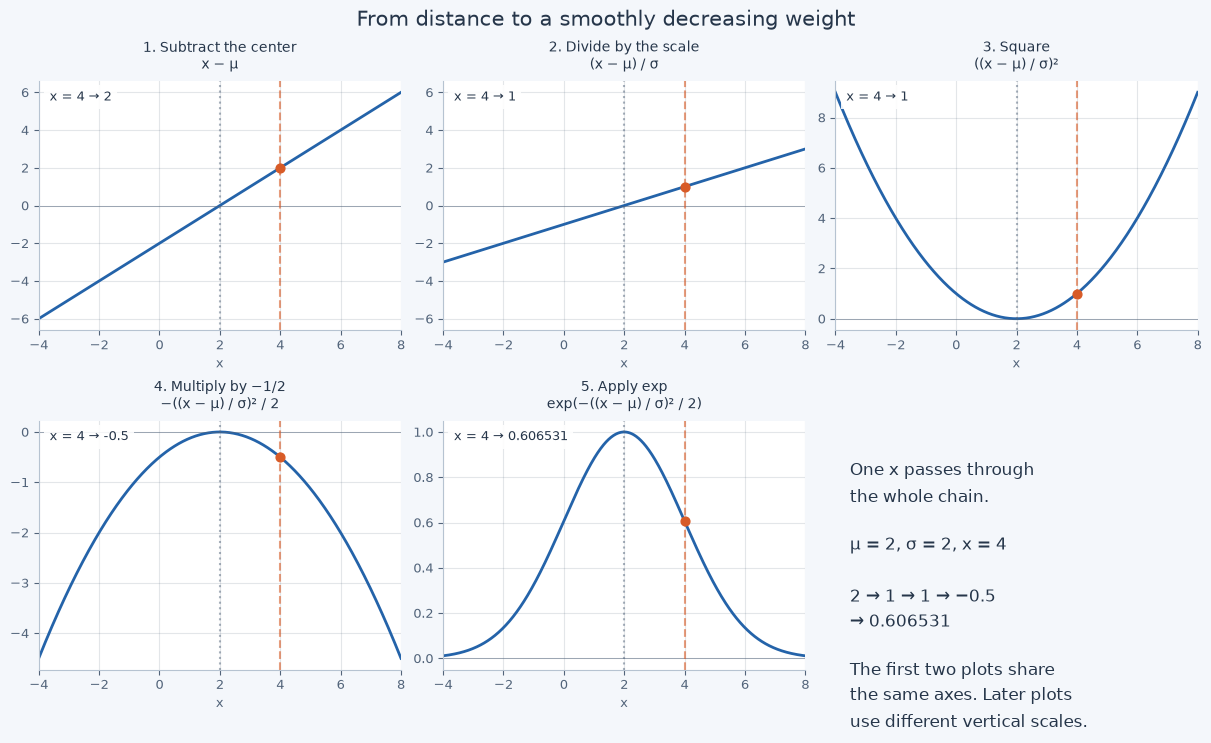

In [5]:
display(construction_figure(language=LANG))

## 9. Complete Calculation: Point 4, Center 2, Width 2

Let's put the calculation for our point into one table. Every step is already familiar:

| Step | Calculation | Meaning |
|---|---|---|
| Displacement | $4-2=2$ | Two units to the right of the center |
| Divide by width | $2/2=1$ | One width from the center |
| Square | $1\cdot1=1$ | The same result on both sides |
| Divide by 2 and negate | $-1/2=-0.5$ | An exponent for a decreasing weight |
| Exponential | $e^{-0.5}\approx0.606531$ | The weight at the selected point |

Thus **$f(4)\approx0.606531$**. On the graph, it is the point's height above coordinate 4. On the strip, it is the corresponding brightness.

Now perform the same calculation in Python. Variable names follow the stages: `offset` is the displacement, `relative` the relative displacement, `squared` its square, `exponent` the power's exponent, and `weight` the final weight. In code, `=` stores the result on the right in the variable on the left.

In [6]:
x = 4.0
mu = 2.0
sigma = 2.0

offset = x - mu
relative = offset / sigma
squared = relative * relative
exponent = -squared / 2
weight = math.exp(exponent)

print(f"x - mu                 = {offset:.6f}")
print(f"(x - mu) / sigma       = {relative:.6f}")
print(f"relative * relative    = {squared:.6f}")
print(f"-squared / 2           = {exponent:.6f}")
print(f"exp(exponent)          = {weight:.6f}")

x - mu                 = 2.000000
(x - mu) / sigma       = 1.000000
relative * relative    = 1.000000
-squared / 2           = -0.500000
exp(exponent)          = 0.606531


### Check the Other Side and the Peak

For $x=0$, $\mu=2$, $\sigma=2$:

$$
d=0-2=-2,\qquad
u=-2/2=-1,\qquad
q=(-1)\cdot(-1)=1,
$$

$$
t=-1/2=-0.5,\qquad
f(0)=e^{-0.5}\approx0.606531.
$$

We got the same weight as on the right. The bell looked symmetric in the plot; now the numbers match too.

For $x=2$, exactly at the center:

$$
d=2-2=0,\qquad
u=0/2=0,\qquad
q=0\cdot0=0,
$$

$$
t=-0/2=0,\qquad
f(2)=e^0=1.
$$

With positive width, the same sequence always holds at the center: zero displacement → zero exponent → weight 1.

For $x=6$: $d=6-2=4$, $u=4/2=2$, $q=2\cdot2=4$, $t=-4/2=-2$, so $f(6)=e^{-2}\approx0.135335$.

For $x=8$: $d=8-2=6$, $u=6/2=3$, $q=3\cdot3=9$, $t=-9/2=-4.5$, so $f(8)=e^{-4.5}\approx0.011109$.

Now let Python go through those steps for all five points. The loop repeats our calculation and collects the results in a table.

In [7]:
mu = 2.0
sigma = 2.0

print(" x    offset  relative  squared  exponent    weight")
for x in [2.0, 4.0, 0.0, 6.0, 8.0]:
    offset = x - mu
    relative = offset / sigma
    squared = relative * relative
    exponent = -squared / 2
    weight = math.exp(exponent)
    print(
        f"{x:3.0f}  {offset:8.1f}  {relative:8.1f}  "
        f"{squared:7.1f}  {exponent:8.1f}  {weight:10.6f}"
    )

 x    offset  relative  squared  exponent    weight
  2       0.0       0.0      0.0      -0.0    1.000000
  4       2.0       1.0      1.0      -0.5    0.606531
  0      -2.0      -1.0      1.0      -0.5    0.606531
  6       4.0       2.0      4.0      -2.0    0.135335
  8       6.0       3.0      9.0      -4.5    0.011109


## 10. What Width Changes and Why the Formula Contains a Two

First, keep $x=4$ and $\mu=2$, but change the width from 2 to 1:

$$
d=4-2=2,\quad
u=2/1=2,\quad
q=2\cdot2=4,\quad
t=-4/2=-2,
$$

$$
f(4)=e^{-2}\approx0.135335.
$$

The weight went from 0.606531 to 0.135335. We didn't move the point, but narrowing the bell put it farther from the center **in units of width**. Its weight fell, while the weight at the center stayed at 1.

Now return to $\sigma=2$, but temporarily remove the divisor 2 from the exponent. At $x=4$, the relative displacement is 1:

- with the divisor: exponent $-1/2=-0.5$, weight approximately 0.606531;
- without the divisor: exponent $-1=-1$, weight approximately 0.367879.

Remove the divisor, and the weight falls off faster. We've effectively narrowed the bell without changing the number in the width setting.

We can obtain the same narrower profile while keeping the usual formula and changing its width. Check with numbers. With the old width 2 and the divisor removed, the denominator is $2^2=4$. In the usual formula, we need a new positive scale $w$ such that:

$$
2w^2=4.
$$

Here, $w$ is just a name for the new width. Divide both sides by 2: $w^2=2$. Therefore $w=\sqrt{2}\approx1.414214$. This is less than 2.

The factor $1/2$ is therefore **part of a scale convention**, not the only possible way to draw a bell. In statistics, the scale $\sigma$ under this convention equals the standard deviation of the corresponding normalized Gaussian. You do not need to calculate statistical deviations from data in this lesson: here, the user supplies $\sigma$.

On the left, we change the width in the same formula. On the right, we keep the width setting and look at what happens when we remove the two.

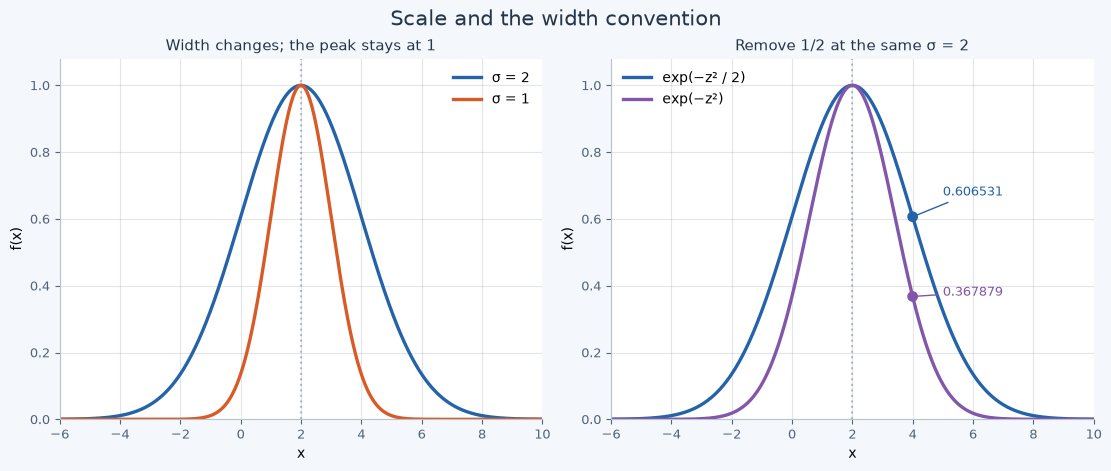

In [8]:
display(width_figure(language=LANG))

## 11. What Our Weight Actually Tells Us

Our Gaussian always has a peak of 1. It's called **unnormalized**: we haven't added a factor to make the area under its graph equal to one. Let's see why that distinction matters.

Imagine coloring in the area under the curve. Stretch the bell horizontally and keep its height, and the colored area grows. That's fine for our weight. If we were building a probability density, we'd need to keep that area equal to one; that isn't our task yet.

Our 0.606531 tells us how strong the influence is at this point relative to the center. We can't read it as “a 60.6531% probability of being at exactly this point.” We haven't calculated the Gaussian's full opacity or the final pixel color either.

Later, we'll add color, an opacity parameter, and blending with neighboring Gaussians. For now, we needed to understand one part: **how influence decreases smoothly as we move away from the center**.

A flashlight's spot helps us picture this. A real flashlight may have a different profile, though: the formula we just unpacked defines the exact shape of our spot.

## 12. Zero Width, Negative Coordinates, and the Tails of the Bell

**Use a width greater than zero.** With $\sigma=0$, we would have to divide by zero. The formula is undefined even at the center, where it would require $0/0$. We won't use −2 as a width either. Squaring it would give the same profile as 2, but a negative length isn't useful here. We'll stick to $\sigma>0$.

**Coordinates can be negative.** If $x$ or the center $\mu$ is below zero, we've simply picked a mark to the left of zero on the ruler. The restriction on the sign of the width doesn't apply to coordinates.

**The weight cannot exceed 1.** A square is nonnegative, so after division and negation the exponent is at most zero. For the positive exponential, exponent zero gives 1 and a negative exponent gives less than 1.

**The bell doesn't end at three widths.** At distance $3\sigma$, the weight is $e^{-4.5}\approx0.011109$. At $4\sigma$: relative displacement 4 → square 16 → exponent $-16/2=-8$ → weight $e^{-8}\approx0.000335$.

In exact mathematics, any finite coordinate and positive finite width produce a weight greater than zero. On a computer, an extremely small value can round down to zero because numbers have limited storage precision. That is a computational limit, not a break in the mathematical curve.

Renderers sometimes discard weak tails to produce images faster. But a distance of $3\sigma$ alone cannot tell us that a contribution is safe to ignore. We also need to consider opacity, neighboring elements, and how accurate we want the image to be.

## 13. Your Own Function and Experiments

Let's put our operations into a function. Pass in `x`, `mu`, and `sigma`, and it returns the weight. The line with `sigma <= 0` checks the width: if it's zero or negative, the function stops and shows an error.

For these experiments, use ordinary finite numbers, without infinity or special values such as `NaN`. Each of the five operations has its own line, so you can work down the code and compare it with the calculation.

In [9]:
def gaussian_weight(x, mu, sigma):
    if sigma <= 0:
        raise ValueError("sigma must be greater than zero")

    offset = x - mu
    relative = offset / sigma
    squared = relative * relative
    exponent = -squared / 2
    return math.exp(exponent)


x = 4.0
mu = 2.0
sigma = 2.0

print(f"weight = {gaussian_weight(x, mu, sigma):.6g}")

weight = 0.606531


Before each change, try to predict the result. Then run the code and compare:

| Change one value; leave the others at their defaults | What to check |
|---|---|
| `x = 0.0` | Does the weight equal the value at 4? Why? |
| `mu = 4.0` | What weight will the selected point at 4 have? |
| `sigma = 1.0` | Will the weight at 4 increase or decrease? |
| `sigma = 4.0` | How far away is the point in units of width now? |
| `sigma = 0.0` | Why should the function stop rather than produce an image? |

Change one parameter at a time and restore the defaults before the next experiment. If the values fit within the slider ranges, set them in the lab at the start of the lesson too. The plot should show the same result. The sliders stop before μ = 4 and σ = 4, although the formula works with those values. For these, change the arguments of the first gaussian_figure call in the initial graph cell: for example, mu=4, sigma=2, x=4 or mu=2, sigma=4, x=4.

Try zero width only in gaussian_weight. It should respond with ValueError: we are deliberately checking the protection against division by zero. There is no plot for this case. Restore sigma=2 afterwards so subsequent runs finish without an error.

<details>
<summary>Answers to the parameter experiments</summary>

**Point on the left, $x=0$.** Displacement $0-2=-2$, relative displacement $-2/2=-1$, square $(-1)^2=1$, exponent $-1/2=-0.5$. The weight is $e^{-0.5}\approx0.606531$. Squaring gives the same result as for $x=4$.

**Center at the measurement point, $\mu=4$.** Displacement $4-4=0$, division $0/2=0$, square 0, exponent 0. The weight is $e^0=1$. We moved the whole bell so that the selected point became its peak.

**Width $\sigma=1$.** Displacement $4-2=2$, relative displacement $2/1=2$, square 4, exponent −2. The weight is $e^{-2}\approx0.135335$. The bell became narrower, and this point's weight decreased.

**Width $\sigma=4$.** Displacement 2, relative displacement $2/4=0.5$, square $0.5\cdot0.5=0.25$, exponent $-0.25/2=-0.125$. The weight is $e^{-0.125}\approx0.882497$. The point is only half a width from the center, so its weight increased.

**Width $\sigma=0$.** The operation $2/0$ is already undefined. The check stops the function before division. This is not weight 0, infinite weight, or a valid Gaussian.

</details>

### How to Read Very Small Numbers

The lab may show a small number as `1.523e-8`. Here, the letter `e` is **part of Python's number notation**, not a separate factor $e\approx2.71828$.

Read it as “1.523 times ten to the power of minus eight”:

$$
1.523\mathrm{e}{-8}
=1.523\cdot10^{-8}
=\frac{1.523}{100\,000\,000}
=0.00000001523.
$$

We already know how to read negative powers: $10^{-8}$ is one divided by eight tens multiplied together. This format shows a small positive result without a long string of zeros.

In the tables above, `.6f` rounds printed output to six decimal places. A very small number can therefore appear as `0.000000` while remaining positive internally. The last function's output uses `.6g`: six significant digits, switching to the short notation when needed. Rounding the display is different from an actual value rounding down to zero inside a calculation.

## 14. Check Your Understanding

First explain what you expect to see in the plot, then check it with a calculation. If you get stuck, return to the five steps: subtract, divide, square, divide by 2 and negate, then calculate the exponential.

### Exercise 1. The Same Coordinates in Different Units

In the first case, $x=4$ cm, $\mu=2$ cm, $\sigma=2$ cm. In the second, the same quantities are written in meters: $x=0.04$, $\mu=0.02$, $\sigma=0.02$. Does the weight change?

<details>
<summary>Worked answer</summary>

In centimeters, displacement is $4-2=2$, and relative displacement is $2/2=1$. Then the square is 1, the exponent is −0.5, and the weight is approximately 0.606531.

In meters, displacement is $0.04-0.02=0.02$, and relative displacement is $0.02/0.02=1$. Every following operation is identical: square 1, exponent −0.5, weight approximately 0.606531.

The physical position relative to the width did not change. Only the way we wrote the lengths changed. Convert **all three** quantities: do not mix centimeters and meters in one ratio.

</details>

### Exercise 2. What Breaks Without the Square?

Use center 2 and width 2. For points 4 and 0, skip squaring the relative displacement: divide it directly by 2, negate it, and calculate the exponential. Will symmetry and a peak of 1 survive?

<details>
<summary>Worked answer</summary>

For point 4: displacement $4-2=2$, relative displacement $2/2=1$. Without squaring, the exponent is $-1/2=-0.5$, and the result is approximately 0.606531.

For point 0: displacement $0-2=-2$, relative displacement $-2/2=-1$. Without squaring, the exponent is $-(-1)/2=+0.5$, and the result is $e^{0.5}=\sqrt{e}\approx1.648721$.

Equal distances give different values. On the left, the weight even exceeds 1 and becomes greater than the center's value. We've lost our symmetric bell. That's why we needed the square.

</details>

### Exercise 3. What Breaks Without the Minus Sign?

Keep the square this time, but remove the minus sign before division. Compare the center with a point one width away.

<details>
<summary>Worked answer</summary>

At the center, relative displacement is 0, its square is 0, and the exponent is $0/2=0$. The result is 1.

One width away, relative displacement is 1 or −1; either square is 1. Without the minus sign, the exponent is $1/2=+0.5$, giving approximately 1.648721. Two widths away, the square is 4, the exponent is $4/2=2$, and the result is $e^2\approx7.389056$.

Influence grows with distance. Symmetry remains, but the center becomes a minimum. The minus sign converted the increasing squared separation into a decreasing weight.

</details>

### Exercise 4. If Width Doubles, Does the Peak Become Half as High?

And can we say that the Gaussian ends beyond three widths?

<details>
<summary>Worked answer</summary>

No. At the center, $x=\mu$, so displacement is 0. For any positive width, $0/\sigma=0$, the square is 0, the exponent is 0, and the result is $e^0=1$. Increasing width stretches the profile without changing our fixed peak height.

At three widths, relative displacement is 3, its square is 9, the exponent is −4.5, and the weight is approximately 0.011109. It is small but positive. Farther away, the weight keeps decreasing smoothly rather than stopping. Truncating the tail is a separate approximation in a particular program, not a property of the formula.

</details>

## 15. From the Plot to the Calculation and Back

We started with a bell curve and sliders. Now we can take any valid coordinate and work out the weight ourselves:

**subtract the center → divide by width → square → divide by 2 and negate → calculate the exponential.**

Return to the first plot and try to connect what it does with the calculation:

- why changing $\mu$ moves the bell;
- why increasing $\sigma$ widens it while preserving a peak of 1;
- why equal distances to the left and right have equal values;
- why the minus sign does not make the final result negative;
- what the exponential, square, and factor $1/2$ do;
- why a weight is not a probability and why $3\sigma$ is not a sharp boundary.

If something is still unclear, take the relevant example and calculate it for a different point. It's easier to see which operation changes the result that way than to memorize the whole formula at once.

In the next lesson, we add a second coordinate: a profile along a line becomes a spot on a plane. We will first see it as an image and a hill, then investigate how to combine two familiar one-dimensional scales.

[Return to the course outline](../../README.md)